# 05 - Sensitivity: Which Hand-Set Constants Actually Matter?

Scales every numeric class constant of `MatchRatingsService` down and up by a relative step (default +/-20%), re-rates the whole pool, and measures
how far ratings move from the baseline. One constant at a time, everything else at its live value. Variants are throwaway subclasses that override class
constants (`workshop/lib/sweep.py`); nothing in `src/` is modified, and the base class is checked unchanged by a test.

**How to read the table.**

| Column | Meaning |
|---|---|
| `effect` | larger of the down/up mean absolute rating change (the sort key) |
| `down_mean_abs`, `up_mean_abs` | mean absolute change when scaled down / up |
| `mean_shift_down`, `mean_shift_up` | signed mean change: does it lift or lower ratings overall? |
| `worst_rank_corr` | Spearman correlation with the baseline ordering (1.0 = same ranking) |
| `max_share_changed` | largest share of ratings that change at all (ratings are rounded to 0.1) |
| `max_share_moved_0_5` | largest share that move by half a point or more |
| `max_abs_change` | biggest single rating change |

**Not covered.** Constants hard-coded inside method bodies (sigmoid k, the supremacy gamma and caps, mastery thresholds, goalkeeper internals, volume
masks) cannot be swept this way, and one-at-a-time sweeps miss interactions. Step sizes are judgement calls (`sweep.STEPS`).

In [1]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

project_root = Path("..").resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from workshop.lib import crossval, datasets, decompose, fit, gate, inference, rating, refit, sweep, variants
from workshop.lib.report import ci, header, say

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
info = header()

**Validated config: `005d563f`** | run 2026-10-25

- Config fitted on: arsenal_2 1-38, ipswich_3 1-22, valencia_cf_1 1-157
- Data analysed (matches per career): arsenal_2 (38), ipswich_3 (22), valencia_cf_1 (157)

## 1. Pool and baseline

In [3]:
pool = sweep.load_pool("pool")
idx = pool.index.assign(rating=pool.baseline)
print(f"{len(pool.records)} performances; {int(np.isfinite(pool.baseline).sum())} rated")
print("Constants swept:", len(sweep.tunable_constants()), "| default step:", sweep.DEFAULT_STEP, "| overrides:", sweep.STEPS)
idx.groupby("career")["rating"].agg(["count", "mean", "std"])

3338 performances; 3259 rated
Constants swept: 51 | default step: 0.2 | overrides: {'CDM_PIVOT_MIN_PASS_ACC': 0.05, 'VERSATILITY_THRESHOLD': 0.1}


,count,mean,std
career,,,
arsenal_2,570,6.646,0.965
ipswich_3,313,6.400,0.890
valencia_cf_1,2376,6.412,0.930


## 2. Tornado on the pooled data

In [4]:
result = sweep.tornado(pool)
summary = sweep.summarise(result)
summary.head(25)

,effect,down_mean_abs,up_mean_abs,mean_shift_down,mean_shift_up,worst_rank_corr,max_share_changed,max_share_moved_0_5,max_abs_change
label,,,,,,,,,
XT_POSITION_SCALARS,0.035,0.033,0.035,-0.033,0.035,0.998,0.308,0.000,0.400
DUMMY_WEIGHTS,0.031,0.031,0.028,0.024,-0.021,0.998,0.297,0.000,0.200
CS_RATIOS,0.020,0.020,0.019,-0.020,0.019,0.998,0.188,0.000,0.200
CS_CB_LOW_XG,0.013,0.013,0.013,-0.013,0.013,0.999,0.122,0.000,0.200
GOAL_ALPHA,0.013,0.013,0.012,-0.013,0.012,0.999,0.096,0.000,0.300
ASSIST_GAMMA,0.010,0.010,0.010,-0.010,0.010,0.999,0.085,0.000,0.400
FB_STYLE_HIGH,0.007,0.007,0.006,0.007,-0.006,1.000,0.037,0.002,0.600
DEF_QUALITY_HIGH,0.007,0.007,0.005,0.007,-0.005,1.000,0.051,0.000,0.300
DEF_QUALITY_WEIGHT,0.006,0.006,0.006,-0.006,0.006,1.000,0.052,0.000,0.200


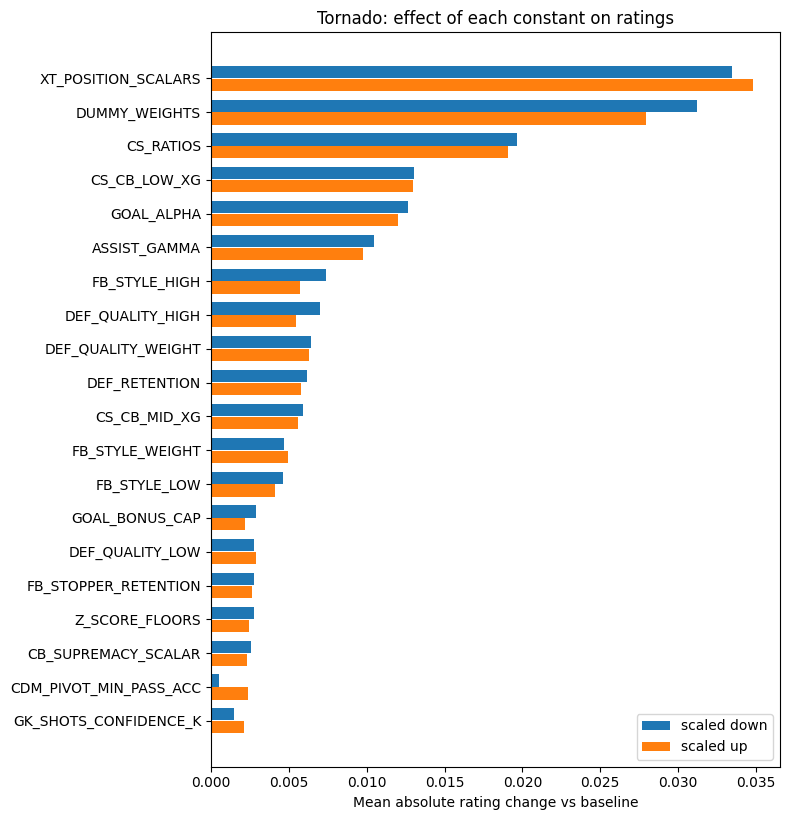

In [5]:
fig = sweep.plot_tornado(summary, top=20)
plt.show()

In [6]:
dead = summary[(summary["effect"] == 0) & (summary["max_share_changed"] == 0)]
top = summary.head(6)
say(
    f"**Which constants matter.** Of {len(summary)} constants, the largest effects (mean absolute rating change at +/-20%) are "
    + ", ".join(f"**{n}** {r['effect']:.3f}" for n, r in top.iterrows())
    + f". The largest single-rating change from any one constant is {summary['max_abs_change'].max():.1f}, and "
    f"{(summary['max_share_moved_0_5'] > 0).sum()} constant(s) move any rating by half a point or more. The lowest rank correlation with the baseline "
    f"ordering is {summary['worst_rank_corr'].min():.3f}. **{len(dead)}** constant(s) have no effect on any rating"
    + (f" ({', '.join(dead.index)}): unreachable in the data, or dead." if len(dead) else ".")
)

**Which constants matter.** Of 51 constants, the largest effects (mean absolute rating change at +/-20%) are **XT_POSITION_SCALARS** 0.035, **DUMMY_WEIGHTS** 0.031, **CS_RATIOS** 0.020, **CS_CB_LOW_XG** 0.013, **GOAL_ALPHA** 0.013, **ASSIST_GAMMA** 0.010. The largest single-rating change from any one constant is 0.6, and 2 constant(s) move any rating by half a point or more. The lowest rank correlation with the baseline ordering is 0.998. **9** constant(s) have no effect on any rating (COLLAPSE_PENALTY, DEFAULT_DUMMY, ST_BLACKHOLE_MIN_POSS_LOST, DEF_RETENTION_LOW_XG_UPLIFT, ST_BLACKHOLE_CAP, ST_WASTEFUL_CAP, ST_BLACKHOLE_MIN_RATIO, ST_BLACKHOLE_SCALE, ST_WASTEFUL_MIN_SHOTS): unreachable in the data, or dead.

## 3. Does the ranking of constants hold in every career?

Tornado effects per career. A constant that matters a lot in one career and little in another is carrying a save-specific effect.

In [7]:
effects = {}
for career in datasets.career_names("pool"):
    effects[career] = sweep.summarise(sweep.tornado(sweep.load_pool(names=[career])))["effect"]
by_career = pd.DataFrame(effects).assign(pooled=summary["effect"]).sort_values("pooled", ascending=False)
display(by_career.head(15))
corr = by_career.corr(method="spearman")
corr

,arsenal_2,ipswich_3,valencia_cf_1,pooled
label,,,,
XT_POSITION_SCALARS,0.051,0.039,0.031,0.035
DUMMY_WEIGHTS,0.037,0.029,0.030,0.031
CS_RATIOS,0.016,0.005,0.022,0.020
CS_CB_LOW_XG,0.010,0.000,0.015,0.013
GOAL_ALPHA,0.016,0.011,0.012,0.013
ASSIST_GAMMA,0.011,0.010,0.011,0.010
FB_STYLE_HIGH,0.010,0.002,0.008,0.007
DEF_QUALITY_HIGH,0.006,0.009,0.007,0.007
DEF_QUALITY_WEIGHT,0.006,0.005,0.007,0.006


,arsenal_2,ipswich_3,valencia_cf_1,pooled
arsenal_2,1.000,0.702,0.925,0.940
ipswich_3,0.702,1.000,0.740,0.761
valencia_cf_1,0.925,0.740,1.000,0.994
pooled,0.940,0.761,0.994,1.000


In [8]:
careers = [c for c in by_career.columns if c != "pooled"]
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(careers) for b in careers[i + 1:]]
ratio = (by_career[careers].max(axis=1) / by_career[careers].min(axis=1).replace(0, np.nan)).dropna().sort_values(ascending=False)
say(
    "**Across careers.** Spearman correlation between the constants' effect rankings: "
    + ", ".join(f"{a} vs {b} {v:.2f}" for a, b, v in pairs)
    + f". The constant whose effect differs most between careers is **{ratio.index[0]}** (largest/smallest effect ratio {ratio.iloc[0]:.1f}x)."
)

**Across careers.** Spearman correlation between the constants' effect rankings: arsenal_2 vs ipswich_3 0.70, arsenal_2 vs valencia_cf_1 0.92, ipswich_3 vs valencia_cf_1 0.74. The constant whose effect differs most between careers is **FB_STYLE_WEIGHT** (largest/smallest effect ratio 7.7x).

## 4. Where does the effect land? (by position group, +20%)

In [9]:
top5 = [n for n in summary.index if summary.loc[n, "effect"] > 0][:5]
by_group = pd.DataFrame({name: sweep.effect_by_group(pool, name, 1.2) for name in top5}).fillna(0)
by_group

,XT_POSITION_SCALARS,DUMMY_WEIGHTS,CS_RATIOS,CS_CB_LOW_XG,GOAL_ALPHA
group,,,,,
CAM,0.055,0.021,0.000,0.000,0.028
CB,0.035,0.029,0.046,0.031,0.001
CDM,0.018,0.027,0.024,0.015,0.000
CM,0.031,0.028,0.017,0.013,0.013
FB/WB,0.079,0.034,0.031,0.022,0.001
GK,0.000,0.000,0.000,0.000,0.000
ST,0.013,0.032,0.000,0.000,0.039
WM,0.037,0.019,0.001,0.000,0.014
Winger,0.029,0.031,0.000,0.000,0.029


In [10]:
say(
    "**By position (mean absolute change at +20%).** "
    + "; ".join(f"{n}: most in {by_group[n].idxmax()} ({by_group[n].max():.3f})" for n in by_group.columns) + "."
)

**By position (mean absolute change at +20%).** XT_POSITION_SCALARS: most in FB/WB (0.079); DUMMY_WEIGHTS: most in FB/WB (0.034); CS_RATIOS: most in CB (0.046); CS_CB_LOW_XG: most in CB (0.031); GOAL_ALPHA: most in ST (0.039).

## 5. Goal and assist constants, one position at a time

Whole-mapping rows hide which position carries the effect, and the goal alphas and assist gammas are the hand-set values most likely to be revisited.

In [11]:
split = ["GOAL_ALPHA", "ASSIST_GAMMA"]
split_summary = sweep.summarise(sweep.tornado(pool, constants=split, split=split))
split_summary[["effect", "max_share_changed", "max_abs_change"]].head(15)

,effect,max_share_changed,max_abs_change
label,,,
GOAL_ALPHA[RW],0.005,0.037,0.300
ASSIST_GAMMA[RW],0.005,0.035,0.400
GOAL_ALPHA[ST],0.004,0.033,0.300
ASSIST_GAMMA[CM],0.003,0.025,0.300
GOAL_ALPHA[CM],0.003,0.021,0.300
ASSIST_GAMMA[ST],0.001,0.010,0.200
ASSIST_GAMMA[RB],0.001,0.008,0.200
ASSIST_GAMMA[CDM],0.001,0.006,0.200
ASSIST_GAMMA[RM],0.000,0.003,0.200


In [12]:
s = split_summary.head(4)
say(
    "**Per-position goal/assist constants.** The four with the largest effect are "
    + ", ".join(f"{n} ({r['effect']:.3f}, {r['max_share_changed']:.1%} of ratings change)" for n, r in s.iterrows()) + "."
)

**Per-position goal/assist constants.** The four with the largest effect are GOAL_ALPHA[RW] (0.005, 3.7% of ratings change), ASSIST_GAMMA[RW] (0.005, 3.5% of ratings change), GOAL_ALPHA[ST] (0.004, 3.3% of ratings change), ASSIST_GAMMA[CM] (0.003, 2.5% of ratings change).

## Notes and limitations

- One at a time: interactions between constants are not captured.
- Ranges are judgement calls: a constant that looks inert at +/-20% may matter at +/-50%; re-run with `step=` or `steps={...}` to probe.
- Ratings are rounded to 0.1, so small continuous effects show up as a small share of ratings changing rather than a smooth shift.
- The pooled table is dominated by the largest career; section 3 separates careers.

In [13]:
say(
    f"**Summary (config `{info['hash'][:8]}`).** Ratings are insensitive to any single constant at +/-20%: "
    f"at most {summary['effect'].max():.3f} mean absolute change ({summary.index[0]}), {summary['max_abs_change'].max():.1f} for the single most affected rating."
    if summary['max_share_moved_0_5'].max() == 0 else
    f"**Summary (config `{info['hash'][:8]}`).** {int((summary['max_share_moved_0_5'] > 0).sum())} constant(s) move some ratings by half a point or more; "
    f"the largest mean effect is {summary['effect'].max():.3f} ({summary.index[0]})."
)

**Summary (config `005d563f`).** 2 constant(s) move some ratings by half a point or more; the largest mean effect is 0.035 (XT_POSITION_SCALARS).